# LinkML-Map tutorial: using it from Python

This tutorial walks through using LinkML-Map from Python. For most jobs the command line is
enough (see the [Quick Start](../quickstart.md)); use the Python API when a mapping is one step
inside a larger program, or when you want to work with a specification itself.

Every operation here has a command-line equivalent, noted as we go.

In [1]:
import yaml
from linkml_runtime import SchemaView
from linkml_runtime.linkml_model import SlotDefinition
from linkml_runtime.utils.schema_builder import SchemaBuilder

from linkml_map import ObjectTransformer

## Creating an example schema

We will use a LinkML SchemaBuilder object to build a source schema. We'll start with a simple
`Person` schema, with a few single valued scalar slots:

In [2]:
sb = SchemaBuilder()
sb.add_class(
    "Person",
    slots=[
        SlotDefinition("family_name", range="string"),
        SlotDefinition("given_name", range="string"),
        SlotDefinition("age_in_years", range="integer"),
        SlotDefinition("height_in_cm", range="float"),
    ],
)
sb.add_defaults()
source = SchemaView(sb.schema)
print(yaml.dump(sb.as_dict(), sort_keys=False))

name: test-schema
id: http://example.org/test-schema
imports:
- linkml:types
prefixes:
  linkml: https://w3id.org/linkml/
  test_schema: http://example.org/test-schema/
default_prefix: test_schema
default_range: string
slots:
  family_name:
    range: string
  given_name:
    range: string
  age_in_years:
    range: integer
  height_in_cm:
    range: float
classes:
  Person:
    slots:
    - family_name
    - given_name
    - age_in_years
    - height_in_cm



## Creating a transformer

A transformer pairs a *transformation specification* with the source schema it maps from. Our
first specification is a trivial one that:

- maps the `Person` class to an `Individual` class
- passes through the name fields as-is
- renames the measurement fields (`age_in_years` and `height_in_cm` to `age` and `height`)

`ObjectTransformer` takes the specification as a YAML file path, a dict, or a loaded
specification, and the source schema as a path or a `SchemaView`. Here we use a dict:

In [3]:
spec = yaml.safe_load("""
class_derivations:
  Individual:
    populated_from: Person
    slot_derivations:
      family_name:
        populated_from: family_name
      given_name:
        populated_from: given_name
      age:
        populated_from: age_in_years
      height:
        populated_from: height_in_cm
""")

tr = ObjectTransformer(specification=spec, source_schemaview=source)

## Transforming objects

Next we make a `Person` object as a Python dictionary, and map it. `source_type` names the
source class the object belongs to:

In [4]:
person = {
    "given_name": "Jane",
    "family_name": "Doe",
    "age_in_years": 42,
    "height_in_cm": 180.0,
}
tr.map_object(person, source_type="Person")

{'family_name': 'Doe', 'given_name': 'Jane', 'age': 42, 'height': 180.0}

This does what we expect: it renames the two fields and leaves all values intact.

From the command line, with the specification and schema in files:

```bash
linkml-map map-data -T spec.yaml -s schema.yaml --source-type Person person.yaml
```

## Using expressions

In addition to renaming fields, we can derive field values by evaluating *expressions*.
Expressions use a safe subset of Python, with `{slot}` referring to a slot on the source object.
If a specification needs full Python, pass `unrestricted_eval=True` (`--unrestricted-eval` on
the command line), but only for specifications you trust.

In [5]:
spec = yaml.safe_load("""
class_derivations:
  Individual:
    populated_from: Person
    slot_derivations:
      name:
        expr: "{given_name} + ' ' + {family_name}"
      age_in_months:
        expr: "{age_in_years} * 12"
      height_in_meters:
        expr: "{height_in_cm} / 100"
""")

tr = ObjectTransformer(specification=spec, source_schemaview=source)
tr.map_object(person, source_type="Person")

{'name': 'Jane Doe', 'age_in_months': 504, 'height_in_meters': 1.8}

## Typing output to a target schema

Given a target schema, each value is converted to the target slot's range: strings are parsed to
numbers and booleans, and a value for an enum slot is matched against the enum's permissible
values (by key, `meaning`, `title` or alias) and written as the permissible value's key.

Our target schema types `age` as an integer and adds a `status` enum:

In [6]:
target = SchemaView("""
id: https://example.org/individual
name: individual
prefixes:
  linkml: https://w3id.org/linkml/
imports:
  - linkml:types
default_range: string
classes:
  Individual:
    attributes:
      name:
      age:
        range: integer
      status:
        range: StatusEnum
enums:
  StatusEnum:
    permissible_values:
      ADULT:
        aliases: [adult]
      MINOR:
        aliases: [minor, child]
""")

spec = yaml.safe_load("""
class_derivations:
  Individual:
    populated_from: Person
    slot_derivations:
      name:
        expr: "{given_name} + ' ' + {family_name}"
      age:
        populated_from: age_in_years
      status:
        expr: "'adult' if {age_in_years} >= 18 else 'child'"
""")

tr = ObjectTransformer(specification=spec, source_schemaview=source, target_schemaview=target)
tr.map_object({"given_name": "Jane", "family_name": "Doe", "age_in_years": "42"}, source_type="Person")

{'name': 'Jane Doe', 'age': 42, 'status': 'ADULT'}

The age arrived as the string `"42"`, as it would from a TSV, and came out as an integer.
The expression produced `'adult'`, which matched the `ADULT` permissible value by its alias.

A value that matches no permissible value passes through with a warning. With `strict=True`
(`--strict` on the command line) it fails the record instead, which is what you want for real
data:

In [7]:
from linkml_map.transformer.errors import TransformationError

spec["class_derivations"]["Individual"]["slot_derivations"]["status"]["expr"] = (
    "'grown up' if {age_in_years} >= 18 else 'child'"
)
tr = ObjectTransformer(specification=spec, source_schemaview=source, target_schemaview=target, strict=True)
try:
    tr.map_object(person, source_type="Person")
except TransformationError as err:
    print(err)

'grown up' is not a permissible value of enum StatusEnum; class_derivation=Individual (from Person); slot_derivation=status


Most mistakes like this one can be caught before any data is mapped, with
`linkml-map validate-spec`; see the [Command-Line Reference](../cli.md#validate-spec).

## Unit conversions and flattening

The LinkML specification allows schemas to declare the units of slots. Let's add a UCUM code to
`height_in_cm`, and a multivalued `aliases` slot:

In [8]:
from linkml_runtime.linkml_model.units import UnitOfMeasure

sb.schema.slots["height_in_cm"].unit = UnitOfMeasure(ucum_code="cm")
sb.add_slot("aliases", multivalued=True, range="string", replace_if_present=True)
sb.schema.classes["Person"].slots.append("aliases")
source = SchemaView(sb.schema)

Now the specification can ask for a `target_unit` instead of writing the arithmetic, and
can flatten `aliases` into a single delimited string, as a TSV would need:

In [9]:
spec = yaml.safe_load("""
class_derivations:
  Individual:
    populated_from: Person
    slot_derivations:
      family_name:
        populated_from: family_name
      given_name:
        populated_from: given_name
      height_in_meters:
        populated_from: height_in_cm
        unit_conversion:
          target_unit: m
      aliases:
        populated_from: aliases
        stringification:
          delimiter: '|'
""")

tr = ObjectTransformer(specification=spec, source_schemaview=source)
person["aliases"] = ["Janie", "Janey"]
flat = tr.map_object(person, source_type="Person")
flat

{'family_name': 'Doe',
 'given_name': 'Jane',
 'height_in_meters': 1.8,
 'aliases': 'Janie|Janey'}

## Under the hood: working with the specification

A specification is data, not code, so tools can inspect it and reason about it. The classes
below do that; they are what the `derive-schema`, `invert` and `compile` commands use, and you
can call them directly.

### Deriving the target schema

`SchemaMapper` works out the target schema a specification implies for its source schema.
Note that it has inferred the unit of `height_in_meters`:

In [10]:
from linkml_runtime.dumpers import yaml_dumper

from linkml_map.inference.schema_mapper import SchemaMapper

target_schema = SchemaMapper(source_schemaview=source).derive_schema(tr.specification)
print(yaml_dumper.dumps(target_schema))

name: test-schema-derived
id: http://example.org/test-schema-derived
imports:
- linkml:types
prefixes:
  linkml:
    prefix_prefix: linkml
    prefix_reference: https://w3id.org/linkml/
  test_schema:
    prefix_prefix: test_schema
    prefix_reference: http://example.org/test-schema/
default_prefix: http://example.org/test-schema-derived/
default_range: string
classes:
  Individual:
    name: Individual
    attributes:
      family_name:
        name: family_name
        domain_of:
        - Person
        range: string
      given_name:
        name: given_name
        domain_of:
        - Person
        range: string
      height_in_meters:
        name: height_in_meters
        domain_of:
        - Person
        range: float
        unit:
          ucum_code: m
      aliases:
        name: aliases
        domain_of:
        - Person
        range: string
        multivalued: false



### Reversing a transformation

A specification built from renames, unit conversions and stringification can be *inverted*
into one that maps the other way. (Expressions can't be inverted.) The inverse specification's
source schema is the derived target schema:

In [11]:
from linkml_map.inference.inverter import TransformationSpecificationInverter

inverse = TransformationSpecificationInverter(source_schemaview=source).invert(tr.specification)
reverse = ObjectTransformer(specification=inverse, source_schemaview=SchemaView(yaml_dumper.dumps(target_schema)))
reverse.map_object(flat, source_type="Individual")

{'family_name': 'Doe',
 'given_name': 'Jane',
 'height_in_cm': 180.0,
 'aliases': ['Janie', 'Janey']}

The flattened record maps back to the original: the height is back in centimeters and
the aliases are a list again.

### Visualizing a specification

`GraphvizCompiler` draws the source and target classes and the slots mapped between them.
Rendering it needs the [Graphviz](https://graphviz.org/download/) program installed.

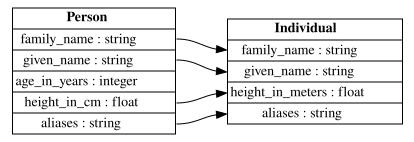

In [12]:
from linkml_map.compiler.graphviz_compiler import GraphvizCompiler

GraphvizCompiler(source_schemaview=source).compile(tr.specification).digraph

## Next steps

- [Writing Specifications](../writing-specs.md): joins, identifiers, and more on target-schema typing
- [Command-Line Reference](../cli.md): every subcommand and option
- The API reference, for the classes used here